### Import all CSV files

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Dataset folder path
data_path = Path(r"C:\Users\hp\OneDrive\Desktop\Food_Delivery_Analytics\Dataset")

# Load CSV files
customers = pd.read_csv(data_path / "customers.csv")
restaurants = pd.read_csv(data_path / "restaurants.csv")
delivery_partners = pd.read_csv(data_path / "delivery_partners.csv")
orders = pd.read_csv(data_path / "orders.csv")
ratings = pd.read_csv(data_path / "ratings.csv")

print("All CSV files loaded successfully!")


All CSV files loaded successfully!


### Check dataset shape

In [13]:

print("Customers:", customers.shape)
print("Restaurants:", restaurants.shape)
print("Delivery Partners:", delivery_partners.shape)
print("Orders:", orders.shape)
print("Ratings:", ratings.shape)


Customers: (4500, 5)
Restaurants: (90, 7)
Delivery Partners: (420, 6)
Orders: (15000, 18)
Ratings: (9844, 7)


### Check first five records

In [15]:

print("ORDERS DATA")
display(orders.head())

print("CUSTOMERS DATA")
display(customers.head())

print("RESTAURANTS DATA")
display(restaurants.head())


ORDERS DATA


,order_id,customer_id,restaurant_id,partner_id,order_datetime,order_status,payment_method,subtotal,delivery_fee,discount,tax,total_amount,estimated_delivery_minutes,actual_delivery_minutes,preparation_time_minutes,delivery_distance_km,cancellation_reason,refund_amount
0,100001,5,70,151,2025-10-15 05:25:01,Delivered,Wallet,996.0,24.0,123.0,49.80,946.80,26,17,41,5.14,Not Cancelled,0.0
1,100002,3376,41,285,2025-06-06 09:24:43,Delivered,Debit Card,239.0,18.0,141.0,11.95,127.95,44,61,31,7.15,Not Cancelled,0.0
2,100003,2722,68,193,2026-02-11 00:59:03,Delivered,Cash,1509.0,23.0,137.0,75.45,1470.45,28,48,21,12.17,Not Cancelled,0.0
3,100004,437,76,246,2025-11-07 15:17:00,Delivered,Cash,732.0,73.0,145.0,36.60,696.60,53,41,16,11.34,Not Cancelled,0.0
4,100005,2248,4,380,2026-04-19 16:30:54,Delivered,Credit Card,403.0,54.0,100.0,20.15,377.15,39,49,23,8.58,Not Cancelled,0.0


CUSTOMERS DATA


,customer_id,customer_name,city,signup_date,customer_segment
0,1,Customer 0001,Pune,2024-01-22,New
1,2,Customer 0002,Chennai,2026-02-06,New
2,3,Customer 0003,Chennai,2026-03-22,Premium
3,4,Customer 0004,Pune,2025-11-12,Regular
4,5,Customer 0005,Delhi,2024-11-05,Regular


RESTAURANTS DATA


,restaurant_id,restaurant_name,cuisine,city,average_menu_price,restaurant_rating,is_active
0,1,North Indian Kitchen 01,Italian,Chennai,276,4.71,1
1,2,Biryani Kitchen 02,Biryani,Pune,132,4.72,1
2,3,Fast Food Kitchen 03,Biryani,Bengaluru,200,4.08,1
3,4,Italian Kitchen 04,Chinese,Delhi,628,3.74,1
4,5,Italian Kitchen 05,Desserts,Bengaluru,341,4.51,1


### Check order status

In [16]:

print(orders["order_status"].value_counts())

print("\nTotal Orders:", len(orders))


order_status
Delivered    13673
Cancelled     1327
Name: count, dtype: int64

Total Orders: 15000


In [17]:
### Check missing values

In [18]:

print("Customers Missing Values:")
print(customers.isnull().sum())

print("\nRestaurants Missing Values:")
print(restaurants.isnull().sum())

print("\nDelivery Partners Missing Values:")
print(delivery_partners.isnull().sum())

print("\nOrders Missing Values:")
print(orders.isnull().sum())

print("\nRatings Missing Values:")
print(ratings.isnull().sum())


Customers Missing Values:
customer_id         0
customer_name       0
city                0
signup_date         0
customer_segment    0
dtype: int64

Restaurants Missing Values:
restaurant_id         0
restaurant_name       0
cuisine               0
city                  0
average_menu_price    0
restaurant_rating     0
is_active             0
dtype: int64

Delivery Partners Missing Values:
partner_id        0
partner_name      0
city              0
vehicle_type      0
partner_rating    0
joining_date      0
dtype: int64

Orders Missing Values:
order_id                      0
customer_id                   0
restaurant_id                 0
partner_id                    0
order_datetime                0
order_status                  0
payment_method                0
subtotal                      0
delivery_fee                  0
discount                      0
tax                           0
total_amount                  0
estimated_delivery_minutes    0
actual_delivery_minutes       0
p

In [19]:
### Check duplicate records

In [20]:

print("Customers Duplicates:", customers.duplicated().sum())
print("Restaurants Duplicates:", restaurants.duplicated().sum())
print("Delivery Partners Duplicates:", delivery_partners.duplicated().sum())
print("Orders Duplicates:", orders.duplicated().sum())
print("Ratings Duplicates:", ratings.duplicated().sum())


Customers Duplicates: 0
Restaurants Duplicates: 0
Delivery Partners Duplicates: 0
Orders Duplicates: 0
Ratings Duplicates: 0


In [21]:
### Convert date columns

In [22]:

customers["signup_date"] = pd.to_datetime(customers["signup_date"])

restaurants["restaurant_rating"] = pd.to_numeric(restaurants["restaurant_rating"])

delivery_partners["joining_date"] = pd.to_datetime(delivery_partners["joining_date"])

orders["order_datetime"] = pd.to_datetime(orders["order_datetime"])

ratings["rating_datetime"] = pd.to_datetime(ratings["rating_datetime"])

print("Date columns converted successfully!")


Date columns converted successfully!


In [23]:
### Check data types

In [24]:

print(orders.dtypes)


order_id                               int64
customer_id                            int64
restaurant_id                          int64
partner_id                             int64
order_datetime                datetime64[ns]
order_status                          object
payment_method                        object
subtotal                             float64
delivery_fee                         float64
discount                             float64
tax                                  float64
total_amount                         float64
estimated_delivery_minutes             int64
actual_delivery_minutes                int64
preparation_time_minutes               int64
delivery_distance_km                 float64
cancellation_reason                   object
refund_amount                        float64
dtype: object


In [25]:
### Create cleaned datasets

In [26]:

customers_clean = customers.drop_duplicates().copy()
restaurants_clean = restaurants.drop_duplicates().copy()
delivery_partners_clean = delivery_partners.drop_duplicates().copy()
orders_clean = orders.drop_duplicates().copy()
ratings_clean = ratings.drop_duplicates().copy()

print("Data cleaning completed!")


Data cleaning completed!


In [27]:
### Exploratory Data Analysis (EDA)

In [28]:
### Total Orders

In [29]:

total_orders = len(orders_clean)

print("Total Orders:", total_orders)


Total Orders: 15000


In [34]:
### Order Status Analysis

In [31]:

order_status = orders_clean["order_status"].value_counts()

print(order_status)


order_status
Delivered    13673
Cancelled     1327
Name: count, dtype: int64


In [33]:
### Total Revenue

In [35]:

delivered_orders = orders_clean[
    orders_clean["order_status"] == "Delivered"
]

total_revenue = delivered_orders["total_amount"].sum()

print("Total Revenue: ₹", round(total_revenue, 2))


Total Revenue: ₹ 13637154.15


In [36]:
### Average Order Value (AOV)

In [37]:

average_order_value = delivered_orders["total_amount"].mean()

print("Average Order Value: ₹", round(average_order_value, 2))


Average Order Value: ₹ 997.38


In [38]:
### Cancellation Rate

In [39]:

cancelled_orders = orders_clean[
    orders_clean["order_status"] == "Cancelled"
]

cancellation_rate = (
    len(cancelled_orders) / total_orders
) * 100

print("Cancellation Rate:", round(cancellation_rate, 2), "%")


Cancellation Rate: 8.85 %


In [40]:
### Average Delivery Time

In [42]:
average_delivery_time = delivered_orders[
    "actual_delivery_minutes"
].mean()

print("Average Delivery Time:", round(average_delivery_time, 2), "minutes")


Average Delivery Time: 51.66 minutes


In [43]:
### Display All KPIs Together

In [44]:

print("========== FOOD DELIVERY ANALYTICS ==========")

print("Total Orders:", total_orders)
print("Delivered Orders:", len(delivered_orders))
print("Cancelled Orders:", len(cancelled_orders))
print("Total Revenue: ₹", round(total_revenue, 2))
print("Average Order Value: ₹", round(average_order_value, 2))
print("Cancellation Rate:", round(cancellation_rate, 2), "%")
print("Average Delivery Time:", round(average_delivery_time, 2), "minutes")


========== FOOD DELIVERY ANALYTICS ==========
Total Orders: 15000
Delivered Orders: 13673
Cancelled Orders: 1327
Total Revenue: ₹ 13637154.15
Average Order Value: ₹ 997.38
Cancellation Rate: 8.85 %
Average Delivery Time: 51.66 minutes


In [45]:
### Data Visualization

In [46]:
### Delivered vs Cancelled Orders

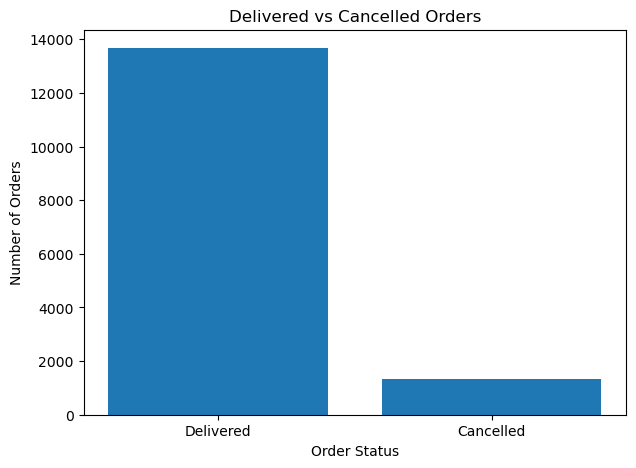

In [47]:

plt.figure(figsize=(7, 5))

order_status = orders_clean["order_status"].value_counts()

plt.bar(order_status.index, order_status.values)

plt.title("Delivered vs Cancelled Orders")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.show()


In [48]:
### Revenue by City

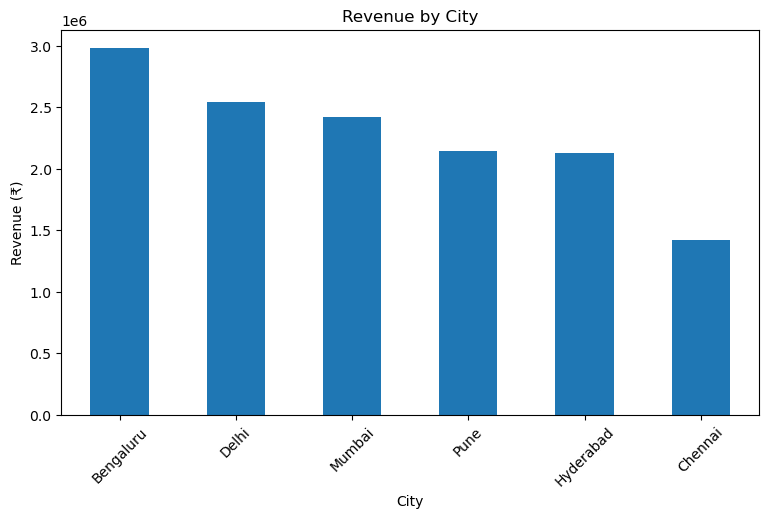

In [49]:

city_data = orders_clean.merge(
    restaurants_clean,
    on="restaurant_id"
)

city_revenue = city_data[
    city_data["order_status"] == "Delivered"
].groupby("city")["total_amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

city_revenue.plot(kind="bar")

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)

plt.show()


In [50]:
### Top 10 Restaurants by Revenue

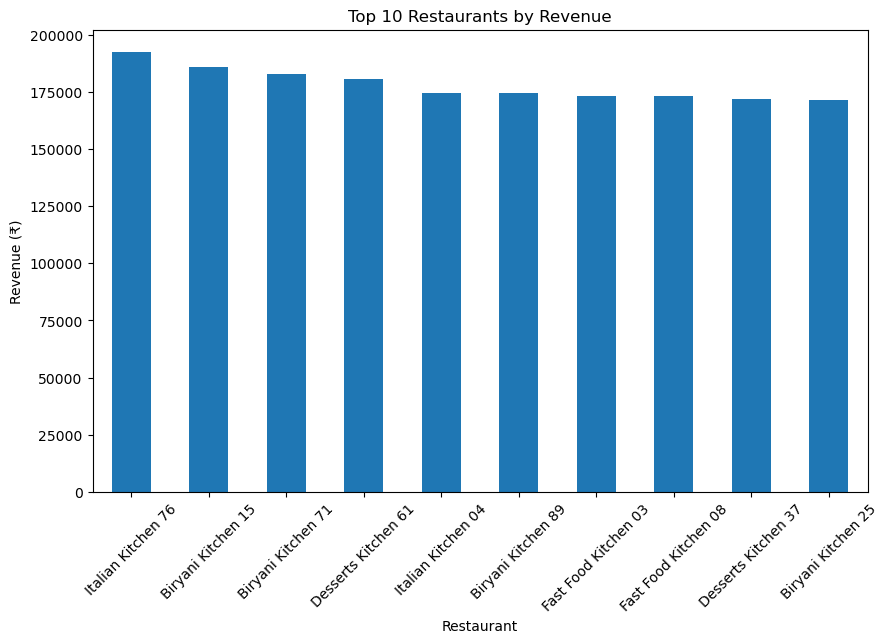

In [51]:

restaurant_revenue = city_data[
    city_data["order_status"] == "Delivered"
].groupby("restaurant_name")["total_amount"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))

restaurant_revenue.plot(kind="bar")

plt.title("Top 10 Restaurants by Revenue")
plt.xlabel("Restaurant")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)

plt.show()


In [52]:
### Monthly Revenue

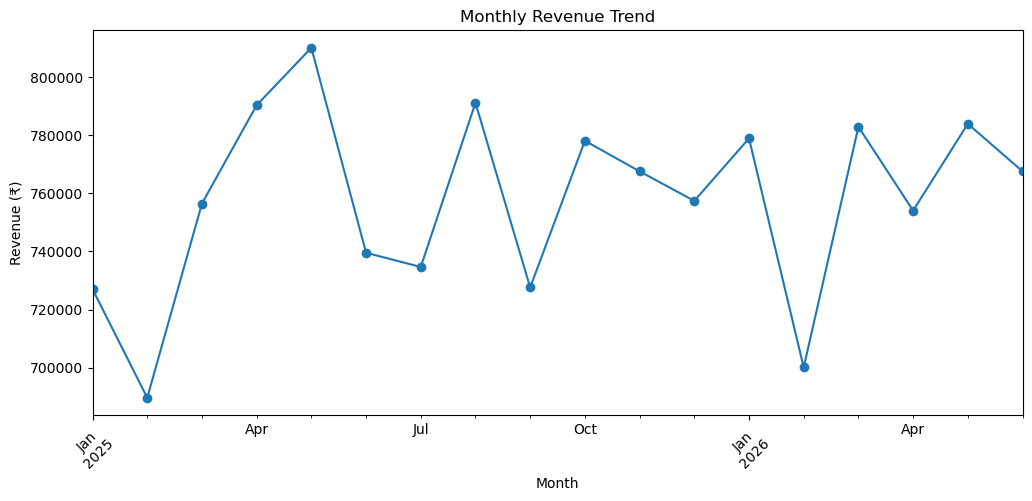

In [53]:

orders_clean["month"] = orders_clean["order_datetime"].dt.to_period("M")

monthly_revenue = orders_clean[
    orders_clean["order_status"] == "Delivered"
].groupby("month")["total_amount"].sum()

plt.figure(figsize=(12, 5))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)

plt.show()


In [54]:
### Peak Ordering Hours

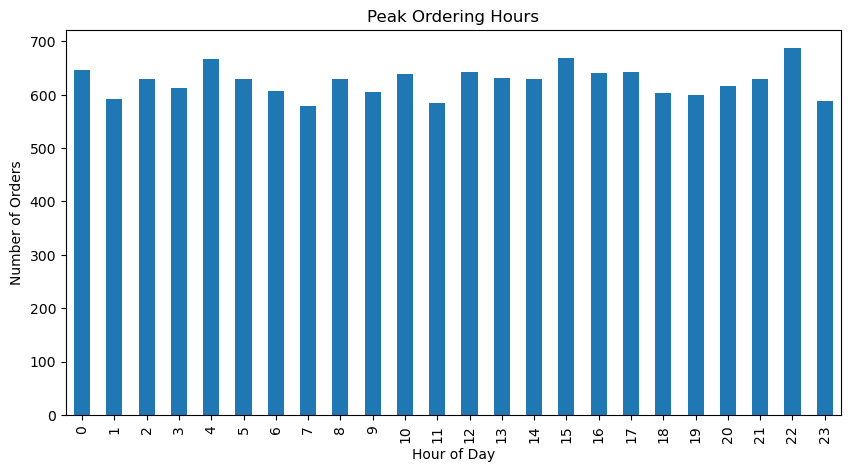

In [55]:

orders_clean["hour"] = orders_clean["order_datetime"].dt.hour

hourly_orders = orders_clean.groupby("hour")["order_id"].count()

plt.figure(figsize=(10, 5))

hourly_orders.plot(kind="bar")

plt.title("Peak Ordering Hours")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")

plt.show()


In [60]:
### Export all five CSV files

In [61]:

from pathlib import Path

export_path = Path(
    r"C:\Users\hp\OneDrive\Desktop\Food_Delivery_Analytics\Dataset\Cleaned_Data")


export_path.mkdir(parents=True, exist_ok=True)

customers_clean.to_csv(export_path / "customers_clean.csv", index=False)

restaurants_clean.to_csv(export_path / "restaurants_clean.csv", index=False)

delivery_partners_clean.to_csv(export_path / "delivery_partners_clean.csv", index=False)

orders_clean.to_csv(export_path / "orders_clean.csv", index=False)

ratings_clean.to_csv(export_path / "ratings_clean.csv", index=False)

print("All cleaned CSV files exported successfully!")


All cleaned CSV files exported successfully!


In [62]:

print("Customers:", len(customers_clean))
print("Restaurants:", len(restaurants_clean))
print("Delivery Partners:", len(delivery_partners_clean))
print("Orders:", len(orders_clean))
print("Ratings:", len(ratings_clean))


Customers: 4500
Restaurants: 90
Delivery Partners: 420
Orders: 15000
Ratings: 9844
